# Demonstrating the different strategies of KBinsDiscretizer: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/preprocessing/plot_discretization_strategies.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/preprocessing/plot_discretization_strategies.html)).

**Scenario:** three 2-D datasets (a uniform square and two `make_blobs` mixtures, 200 samples each) are discretized
with `KBinsDiscretizer(n_bins=4, encode="ordinal", quantile_method="averaged_inverted_cdf", strategy=...)` for
the `uniform`, `quantile` and `kmeans` strategies; each fitted discretizer encodes a 300 x 300 grid that is drawn
as horizontal and vertical stripes.

**Adaptations:**
- Data and grids are generated in Python exactly as in the example and shared as `.npy`; Moxie fits and
  transforms them in Mojo.
- Beyond the example, the Moxie cell also records `inverse_transform` of the grid codes (bin centers) and a
  `encode="onehot-dense"` fit with `get_feature_names_out()`, compared against the same scikit-learn calls.
  sklearn's default `encode="onehot"` produces a sparse matrix, which Moxie does not provide (documented
  deferral); `onehot-dense` is the dense equivalent.
- Plots are drawn smaller (dpi 60) and the Moxie stripes are plotted next to the reference stripes.

**Determinism:** fully deterministic. The data use fixed seeds; uniform and quantile edges are closed-form; the
`kmeans` strategy runs scikit-learn's `KMeans(n_init=1)` from a fixed uniform-midpoint initialisation. The
reference k-means runs with one OpenMP thread (`threadpool_limits(1)`), matching the single-threaded native
Lloyd iteration.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
# The reference is the pinned scikit-learn source (an overlay of the pinned Python
# sources on the installed wheel's compiled extensions), not the installed 1.9.1 wheel.
sys.path.insert(0, str(ROOT / "families/preprocessing/tests/parity"))
import overlay
sklearn = overlay.activate()
print("reference scikit-learn", sklearn.__version__, "from", Path(sklearn.__file__).parent)
%load_ext moxie_nb
nb = moxie_nb.Session("preprocessing/plot_discretization_strategies")

reference scikit-learn 1.10.dev0 from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/families/preprocessing/builds/oracle/sklearn


## 1. scikit-learn (Python reference)

The example code, with the fitted discretizers kept for the parity checks.

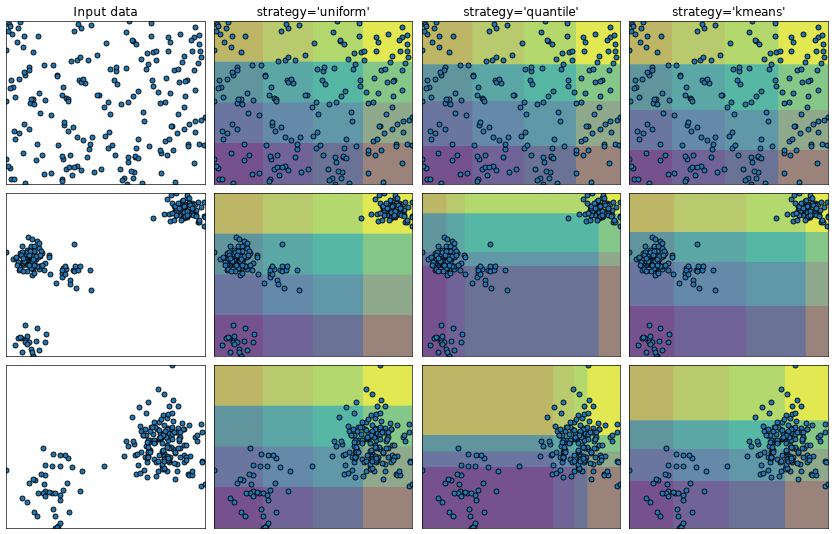

In [2]:
# The pinned sklearn/cluster/__init__.py imports linear_model/manifold modules whose pinned Python
# no longer matches the installed wheel's compiled extensions. Load the pinned k-means module directly,
# exactly as families/preprocessing/tests/parity/test_discretization.py does (that test also checks that
# sklearn/cluster is byte-identical between the pinned revision and the wheel's 1.9.1 tag).
import types
_cluster = types.ModuleType("sklearn.cluster")
_cluster.__path__ = [str(Path(sklearn.__file__).parent / "cluster")]
sys.modules["sklearn.cluster"] = _cluster
from sklearn.cluster._kmeans import KMeans
_cluster.KMeans = KMeans

import matplotlib.pyplot as plt
import numpy as np
from threadpoolctl import threadpool_limits

from sklearn.datasets import make_blobs
from sklearn.preprocessing import KBinsDiscretizer

strategies = ["uniform", "quantile", "kmeans"]

n_samples = 200
centers_0 = np.array([[0, 0], [0, 5], [2, 4], [8, 8]])
centers_1 = np.array([[0, 0], [3, 1]])

# construct the datasets
random_state = 42
X_list = [
    np.random.RandomState(random_state).uniform(-3, 3, size=(n_samples, 2)),
    make_blobs(
        n_samples=[
            n_samples // 10,
            n_samples * 4 // 10,
            n_samples // 10,
            n_samples * 4 // 10,
        ],
        cluster_std=0.5,
        centers=centers_0,
        random_state=random_state,
    )[0],
    make_blobs(
        n_samples=[n_samples // 5, n_samples * 4 // 5],
        cluster_std=0.5,
        centers=centers_1,
        random_state=random_state,
    )[0],
]

sk = {}
grids = []
figure = plt.figure(figsize=(14, 9), dpi=60)
i = 1
for ds_cnt, X in enumerate(X_list):
    ax = plt.subplot(len(X_list), len(strategies) + 1, i)
    ax.scatter(X[:, 0], X[:, 1], edgecolors="k")
    if ds_cnt == 0:
        ax.set_title("Input data", size=14)

    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min(), X[:, 0].max(), 300),
        np.linspace(X[:, 1].min(), X[:, 1].max(), 300),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    grids.append((xx, yy, grid))

    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())

    i += 1
    # transform the dataset with KBinsDiscretizer
    for strategy in strategies:
        enc = KBinsDiscretizer(
            n_bins=4,
            encode="ordinal",
            quantile_method="averaged_inverted_cdf",
            strategy=strategy,
        )
        with threadpool_limits(1):
            enc.fit(X)
        grid_encoded = enc.transform(grid)
        sk[ds_cnt, strategy] = (enc, grid_encoded)

        ax = plt.subplot(len(X_list), len(strategies) + 1, i)

        # horizontal stripes
        horizontal = grid_encoded[:, 0].reshape(xx.shape)
        ax.contourf(xx, yy, horizontal, alpha=0.5)
        # vertical stripes
        vertical = grid_encoded[:, 1].reshape(xx.shape)
        ax.contourf(xx, yy, vertical, alpha=0.5)

        ax.scatter(X[:, 0], X[:, 1], edgecolors="k")
        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_xticks(())
        ax.set_yticks(())
        if ds_cnt == 0:
            ax.set_title("strategy='%s'" % (strategy,), size=14)

        i += 1

plt.tight_layout()
plt.show()

# Extra calls compared below: bin centers and the dense one-hot encoding.
sk_inverse = sk[0, "uniform"][0].inverse_transform(sk[0, "uniform"][1])
onehot = KBinsDiscretizer(n_bins=4, encode="onehot-dense", strategy="uniform").fit(X_list[1])
sk_onehot = onehot.transform(X_list[1])
sk_onehot_names = onehot.get_feature_names_out()

nb.share(**{f"X{d}": X for d, X in enumerate(X_list)},
         **{f"grid{d}": g[2] for d, g in enumerate(grids)})

## 2. Moxie (native Mojo)

The same nine fits and grid encodings through `moxie.preprocessing.KBinsDiscretizer`.

In [3]:
%%mojo discretization
from moxie.preprocessing import KBinsDiscretizer
from moxie_nb_io import load, save, save_strings


def main() raises:
    var strategies: List[String] = ["uniform", "quantile", "kmeans"]
    for d in range(3):
        var X = load("X" + String(d))
        var grid = load("grid" + String(d))
        for s in range(3):
            var enc = KBinsDiscretizer(
                n_bins=4,
                encode="ordinal",
                quantile_method="averaged_inverted_cdf",
                strategy=strategies[s],
            )
            _ = enc.fit(X)
            var tag = String(d) + "_" + strategies[s]
            var codes = enc.transform(grid)
            save("grid_" + tag, codes)
            save("n_bins_" + tag, enc.n_bins_)
            for j in range(2):
                save("edges_" + tag + "_" + String(j), enc.bin_edges_[j])
            if d == 0 and s == 0:
                save("inverse", enc.inverse_transform(codes))

    var onehot = KBinsDiscretizer(n_bins=4, encode="onehot-dense", strategy="uniform")
    var X1 = load("X1")
    _ = onehot.fit(X1)
    save("onehot", onehot.transform(X1))
    save_strings("onehot_names", onehot.get_feature_names_out())
    print("fitted 9 ordinal discretizers and one onehot-dense discretizer")

fitted 9 ordinal discretizers and one onehot-dense discretizer


## 3. Side by side and parity

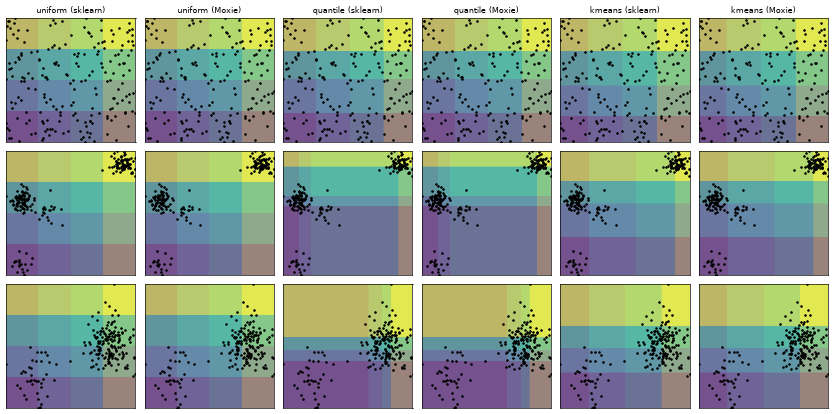

In [4]:
mx = nb.results["discretization"]

fig, axes = plt.subplots(3, 6, figsize=(14, 7), dpi=60)
for d, (xx, yy, grid) in enumerate(grids):
    for s, strategy in enumerate(strategies):
        for side, codes in enumerate([sk[d, strategy][1], mx[f"grid_{d}_{strategy}"]]):
            ax = axes[d, 2 * s + side]
            ax.contourf(xx, yy, codes[:, 0].reshape(xx.shape), alpha=0.5)
            ax.contourf(xx, yy, codes[:, 1].reshape(xx.shape), alpha=0.5)
            ax.scatter(X_list[d][:, 0], X_list[d][:, 1], s=4, c="k")
            ax.set_xticks(()); ax.set_yticks(())
            if d == 0:
                ax.set_title(f"{strategy} ({'sklearn' if side == 0 else 'Moxie'})", size=10)
plt.tight_layout()
plt.show()

moxie_nb.side_by_side(
    sklearn_kmeans_edges=np.vstack([sk[1, "kmeans"][0].bin_edges_[j] for j in range(2)]),
    moxie_kmeans_edges=np.vstack([mx[f"edges_1_kmeans_{j}"] for j in range(2)]))

for d in range(3):
    for strategy in strategies:
        enc, codes = sk[d, strategy]
        tag = f"{d}_{strategy}"
        nb.compare(f"dataset {d} {strategy}: n_bins_", enc.n_bins_, mx[f"n_bins_{tag}"], exact=True)
        for j in range(2):
            nb.compare(f"dataset {d} {strategy}: bin_edges_[{j}]", enc.bin_edges_[j], mx[f"edges_{tag}_{j}"],
                       exact=True, reason="linspace / percentile / single-thread Lloyd replayed operation by operation")
        nb.compare(f"dataset {d} {strategy}: grid codes (90000 x 2)", codes, mx[f"grid_{tag}"], exact=True)
nb.compare("inverse_transform (bin centers), dataset 0 uniform", sk_inverse, mx["inverse"], exact=True,
           reason="(edge[b] + edge[b+1]) * 0.5 in Float64 on both sides")
nb.compare("onehot-dense transform, dataset 1", sk_onehot, mx["onehot"], exact=True)
nb.compare("onehot-dense get_feature_names_out", sk_onehot_names, mx["onehot_names"], exact=True)
nb.note("encode='onehot' (sparse default)", "ADAPTED",
        "sparse output is deferred in Moxie; fit raises a clear ValueError and 'onehot-dense' is the dense equivalent")

sklearn's default `encode="onehot"` returns a SciPy sparse matrix. Moxie has no sparse output, so the default raises clearly at fit:

In [5]:
%%mojo onehot_sparse --expect-fail
from moxie.preprocessing import KBinsDiscretizer
from moxie_nb_io import load


def main() raises:
    var enc = KBinsDiscretizer(n_bins=4)
    _ = enc.fit(load("X0"))

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: ValueError: encode='onehot' returns a sparse matrix and sparse output is deferred; select encode='onehot-dense' or encode='ordinal'



In [6]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
dataset 0 uniform: n_bins_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
dataset 0 uniform: bin_edges_[0],PASS,"(5,)","(5,)",,,exact,0 mismatches,linspace / percentile / single-thread Lloyd replayed operation by operation
dataset 0 uniform: bin_edges_[1],PASS,"(5,)","(5,)",,,exact,0 mismatches,linspace / percentile / single-thread Lloyd replayed operation by operation
dataset 0 uniform: grid codes (90000 x 2),PASS,"(90000, 2)","(90000, 2)",,,exact,0 mismatches,
dataset 0 quantile: n_bins_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
dataset 0 quantile: bin_edges_[0],PASS,"(5,)","(5,)",,,exact,0 mismatches,linspace / percentile / single-thread Lloyd replayed operation by operation
dataset 0 quantile: bin_edges_[1],PASS,"(5,)","(5,)",,,exact,0 mismatches,linspace / percentile / single-thread Lloyd replayed operation by operation
dataset 0 quantile: grid codes (90000 x 2),PASS,"(90000, 2)","(90000, 2)",,,exact,0 mismatches,
dataset 0 kmeans: n_bins_,PASS,"(2,)","(2,)",,,exact,0 mismatches,
dataset 0 kmeans: bin_edges_[0],PASS,"(5,)","(5,)",,,exact,0 mismatches,linspace / percentile / single-thread Lloyd replayed operation by operation
